# Variantes de datos: experimentos A/B sobre el corpus

**Tesis:** *Desarrollo y evaluación de un chatbot educativo basado en IA generativa y RAG para reforzar el aprendizaje de cinemática preuniversitaria en una academia de Chachapoyas* — Elmer Dante Rojas Zuta (MIA-UNI).

En el avance anterior se fijó el buscador (V3: BM25 con raíces + enrutador de subtema). Ahora **el buscador no cambia**: solo cambia **el corpus** que se indexa.

| Variante | Cambio en los datos |
|---|---|
| **D0** baseline | Corpus v5.1 tal cual (título + contenido + ecuaciones + error frecuente) |
| **D1** | Sin campos estructurados (solo título + contenido) |
| **D2** | + hasta 5 problemas reales de la reserva de Ágora por ficha (expansión de documentos) |

El notebook reutiliza `experiments/variantes_datos/ejecutar.py`, así que los números coinciden con el informe. La evaluación final no se usa.

In [1]:
import sys, json, subprocess, importlib.util
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
spec = importlib.util.spec_from_file_location("dv", RAIZ / "experiments/variantes_datos/ejecutar.py")
dv = importlib.util.module_from_spec(spec); spec.loader.exec_module(dv)
fe = dv.fe                                   # funciones del avance de feature engineering
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import eda_utils as u
from rag.metricas import diferencia_pareada, ic_bootstrap
u.estilo(); pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)

corpus0, preguntas, fuente = fe.cargar(None)
dev = preguntas[preguntas.particion == "desarrollo"].reset_index(drop=True)
val = preguntas[preguntas.particion == "validacion"].reset_index(drop=True)
corpus = {v: dv.corpus_variante(v, corpus0) for v in dv.VARIANTES}
titulo = {c["id"]: c["titulo"] for c in corpus0}
print(f"Batería usada: {fuente} · desarrollo {len(dev)} · validación {len(val)}")

Batería usada: completa (privada) · desarrollo 180 · validación 72


## 1. Qué cambia en los datos: la misma ficha en las tres variantes

In [2]:
fid = "CIN-MVCL-T012"
for v in dv.VARIANTES:
    texto = next(c["index_text"] for c in corpus[v] if c["id"] == fid)
    print(f"── {v} · {u.palabras(texto)} palabras ──\n{texto}\n")

── D0 · 125 palabras ──
MVCL — Dos cuerpos en caída libre al mismo tiempo
Si dos cuerpos están en caída libre al mismo tiempo, ambos tienen la misma aceleración g, de modo que la aceleración de uno respecto del otro es cero: visto desde uno de ellos, el otro se mueve con velocidad constante. Por eso, para saber cuándo se encuentran dos cuerpos en la misma vertical, se puede usar la rapidez relativa como en el MRU. Por ejemplo, si uno se suelta desde una altura H y al mismo tiempo otro se lanza desde el suelo hacia arriba con rapidez v, se encuentran en t = H/v.
Relaciones: aceleración relativa = 0 · t = separación vertical / rapidez relativa
Condiciones: Ambos en caída libre durante todo el intervalo, en la misma vertical

── D1 · 103 palabras ──
MVCL — Dos cuerpos en caída libre al mismo tiempo
Si dos cuerpos están en caída libre al mismo tiempo, ambos tienen la misma aceleración g, de modo que la aceleración de uno respecto del otro es cero: visto desde uno de ellos, el otro se mueve

In [3]:
resumen = json.load(open(RAIZ / "data/corpus/variantes/expansion_agora_resumen.json", encoding="utf-8"))
print("Expansión D2 (problemas de la reserva de Ágora que NO están en la batería):")
for k, v in resumen.items(): print(f"  {k}: {v}")

Expansión D2 (problemas de la reserva de Ágora que NO están en la batería):
  reserva_agora: 106
  excluidos_por_parecido: 32
  aceptados: 74
  umbral_jaccard: 0.45
  max_por_ficha: 5
  fichas_expandidas: 48
  problemas_agregados: 104
  jaccard_max_aceptado: 0.448


**Lectura.** D1 quita las líneas «Relaciones» y «Error frecuente». D2 agrega al final enunciados reales de la academia que usan esa ficha. Se descartaron los problemas que se parecían a cualquier pregunta de la batería (Jaccard > 0,45). La expansión solo se usa para **buscar**; al LLM se le entrega la ficha original.

## 2. Un ejemplo: la misma pregunta con cada corpus

In [4]:
ej = val.set_index("id").loc["BAT-MVCL-044"]
print("Pregunta:", ej.enunciado)
print("Fichas correctas:", [f"{f} — {titulo[f]}" for f in ej.unidades_relevantes])
enr = {v: fe.entrenar_enrutador(corpus[v], dev) for v in dv.VARIANTES}
beta = {"D0": 2.0, "D1": 2.0, "D2": 0.5}          # elegidos por CV anidada en desarrollo (se comprueban en la sección 4)
bus = {v: fe.indice({**dv.CFG_V3, "beta_subtema": beta[v]}, corpus[v], enr[v])[0] for v in dv.VARIANTES}
filas = []
for v, b in bus.items():
    top = [d for d, _ in b.buscar(ej.enunciado, 5)]
    filas.append({"variante": v, **{f"{i}.º": f"{'✔ ' if d in ej.unidades_relevantes else ''}{d.split('-')[2]} · {titulo[d]}" for i, d in enumerate(top, 1)}})
pd.DataFrame(filas).set_index("variante")

Pregunta: La esfera A es soltada al mismo tiempo que la esfera B, situada 60 m más abajo en la misma vertical, es lanzada hacia arriba con 30 m/s. Calcule luego de qué tiempo las esferas impactan. (g = 10 m/s²)
Fichas correctas: ['CIN-MVCL-T012 — Dos cuerpos en caída libre al mismo tiempo', 'CIN-MVCL-P004 — Encuentro de dos cuerpos en la misma vertical']


,1.º,2.º,3.º,4.º,5.º
variante,,,,,
D0,"E007 · Velocidad, recorrido y distancia al subir y bajar",T004 · Soltar y lanzar,E006 · Encuentro de dos pelotas en la misma vertical,E002 · Objeto lanzado hacia abajo,E005 · Lanzamiento hacia arriba desde un edificio
D1,"E007 · Velocidad, recorrido y distancia al subir y bajar",T004 · Soltar y lanzar,E006 · Encuentro de dos pelotas en la misma vertical,E002 · Objeto lanzado hacia abajo,E005 · Lanzamiento hacia arriba desde un edificio
D2,✔ T012 · Dos cuerpos en caída libre al mismo tiempo,"E007 · Velocidad, recorrido y distancia al subir y bajar",T006 · Simetría de la subida y la bajada,P003 · Problemas con los números de Galileo en caída libre,✔ P004 · Encuentro de dos cuerpos en la misma vertical


**Lectura.** Con el corpus original, las 5 primeras son casi todas **ejemplos resueltos** (código E): comparten palabras con la pregunta, pero no son las fichas que se necesitan. En D2, las fichas de teoría y procedimiento, ahora acompañadas de problemas reales del mismo tipo, suben a los primeros lugares.

## 3. Holdout de validación: la comparación oficial

In [5]:
res = {v: fe.evaluar(b, val) for v, b in bus.items()}
filas = []
for v, r in res.items():
    lo, hi = ic_bootstrap(r["recall@5"])
    f = {"variante": v, "Recall@5": r["recall@5"].mean(), "IC95": f"[{lo:.3f}; {hi:.3f}]",
         "práctica": r.loc[r.componente == "practica", "recall@5"].mean(), "teoría": r.loc[r.componente == "teoria", "recall@5"].mean(),
         "Recall@10": r["recall@10"].mean(), "MRR@10": r["mrr@10"].mean(), "Fallo@5": r["fallo@5"].mean(),
         "ms/consulta": r.latencia_ms.mean()}
    if v != "D0":
        d = diferencia_pareada(res["D0"]["recall@5"], r["recall@5"])
        f.update({"Δ vs D0": d["diferencia"], "IC95 Δ": f"[{d['ic95'][0]:+.3f}; {d['ic95'][1]:+.3f}]", "p": d["p_bootstrap"]})
    filas.append(f)
pd.DataFrame(filas).set_index("variante").round(3)

,Recall@5,IC95,práctica,teoría,Recall@10,MRR@10,Fallo@5,ms/consulta,Δ vs D0,IC95 Δ,p
variante,,,,,,,,,,,
D0,0.470,[0.361; 0.572],0.324,0.907,0.644,0.376,0.458,1.873,NaN,NaN,NaN
D1,0.491,[0.380; 0.595],0.370,0.852,0.637,0.384,0.444,1.236,0.021,[-0.035; +0.076],0.567
D2,0.611,[0.514; 0.715],0.519,0.889,0.755,0.539,0.319,1.215,0.141,[+0.051; +0.236],0.002


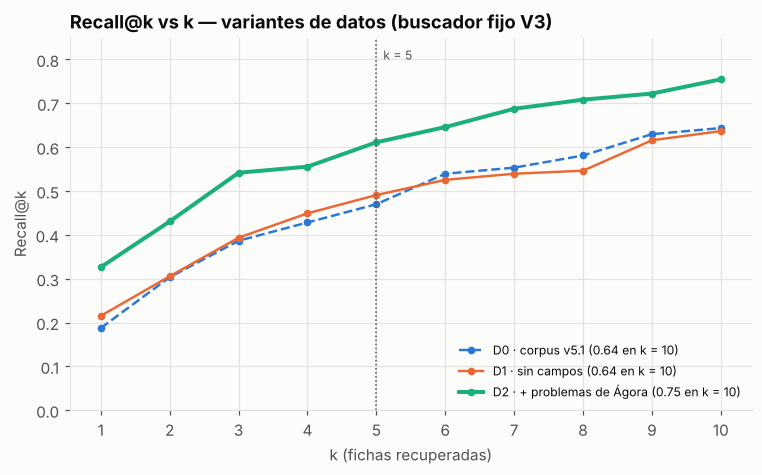

,D0,D1,D2
subtema,,,
MCU,0.63,0.67,0.73
MPCL,0.60,0.67,0.67
MRU,0.61,0.61,0.61
MRUV,0.27,0.27,0.57
MVCL,0.21,0.21,0.46


In [6]:
curva = pd.DataFrame({v: [r[f"recall@{k}"].mean() for k in range(1, 11)] for v, r in res.items()}, index=range(1, 11))
etiq = {"D0": "D0 · corpus v5.1", "D1": "D1 · sin campos", "D2": "D2 · + problemas de Ágora"}
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, v in enumerate(curva.columns):
    ax.plot(curva.index, curva[v], "--" if v == "D0" else "-", marker="o", ms=4, lw=2.6 if v == "D2" else 1.6, color=u.SERIE[i],
            label=f"{etiq[v]} ({curva[v].iloc[-1]:.2f} en k = 10)")
ax.axvline(5, color=u.TINTA_2, ls=":", lw=1); ax.text(5.1, 0.80, "k = 5", color=u.TINTA_2, fontsize=8)
ax.set_xticks(range(1, 11)); ax.set_ylim(0, 0.85); ax.set_xlabel("k (fichas recuperadas)"); ax.set_ylabel("Recall@k")
ax.set_title("Recall@k vs k — variantes de datos (buscador fijo V3)"); ax.legend(loc="lower right", fontsize=8)
plt.show()
pd.DataFrame({v: r.groupby("subtema")["recall@5"].mean() for v, r in res.items()}).round(2)

**Lectura.** D2 queda por encima en todos los valores de k. La mejora se concentra en la práctica y en MRUV y MVCL, los subtemas más débiles del baseline. D1 no cambia de forma significativa y baja algo en teoría.

## 4. Validación cruzada en desarrollo (5 particiones, β con CV anidada)

In [7]:
cvs = []
for v in dv.VARIANTES:
    d, betas = dv.cv(corpus[v], dev); d.insert(0, "variante", v); cvs.append(d)
cvs = pd.concat(cvs)
display(cvs.pivot(index="fold", columns="variante", values="recall@5").round(3))
cvs.groupby("variante")[["recall@5", "recall@10", "mrr@10", "beta"]].agg(["mean", "std"]).round(3)

variante,D0,D1,D2
fold,,,
1,0.500,0.472,0.639
2,0.667,0.639,0.736
3,0.431,0.403,0.486
4,0.519,0.532,0.602
5,0.542,0.569,0.639


recall@5        recall@10        mrr@10        beta       
             mean    std      mean    std   mean    std mean    std
variante                                                           
D0          0.531  0.086     0.665  0.087  0.395  0.084  2.4  0.894
D1          0.523  0.090     0.659  0.081  0.379  0.076  2.0  1.225
D2          0.620  0.090     0.794  0.055  0.510  0.040  0.8  0.274

In [8]:
assert {v: fe.elegir_beta(corpus[v], dev) for v in dv.VARIANTES} == beta   # β final = el usado en las secciones 2 y 3
print("β finales elegidos con todo desarrollo:", beta)

β finales elegidos con todo desarrollo: {'D0': 2.0, 'D1': 2.0, 'D2': 0.5}


**Lectura.** D2 supera a D0 en las **5** particiones. El β que se elige para D2 es menor: con más vocabulario de problemas reales, el enrutador de subtema hace menos falta.

## 5. Sensibilidad: ¿la mejora depende de problemas demasiado parecidos a la batería?

In [9]:
filas = []
for umbral in (0.45, 0.40, 0.35, 0.30):
    c = dv.corpus_variante("D2", corpus0, umbral); b_ = fe.elegir_beta(c, dev)
    r = fe.evaluar(fe.indice({**dv.CFG_V3, "beta_subtema": b_}, c, fe.entrenar_enrutador(c, dev))[0], val)
    d = diferencia_pareada(res["D0"]["recall@5"], r["recall@5"])
    filas.append(dict(umbral_jaccard=umbral, beta=b_, recall5=r["recall@5"].mean(), delta_vs_D0=d["diferencia"], p=d["p_bootstrap"]))
pd.DataFrame(filas).round(3)

,umbral_jaccard,beta,recall5,delta_vs_D0,p
0,0.45,0.5,0.611,0.141,0.002
1,0.40,1.0,0.576,0.106,0.010
2,0.35,1.0,0.576,0.106,0.011
3,0.30,2.0,0.477,0.007,0.906


**Lectura.** Con un filtro más estricto (≤ 0,35), la mejora sigue siendo significativa. Con 0,30 quedan muy pocos problemas y el efecto desaparece: el beneficio viene de la **cantidad de material del mismo tipo**, no de copias. Aun así, se declara como riesgo y se confirmará en la evaluación final.

## 6. Verificación de cero leakage

In [10]:
salida = subprocess.run([sys.executable, str(RAIZ / "experiments/variantes_datos/verificar_fugas.py")], capture_output=True, text=True, cwd=RAIZ)
print(salida.stdout)
assert json.load(open(RAIZ / "experiments/variantes_datos/resultados/verificacion_fugas.json", encoding="utf-8"))["todo_ok"]

bateria_usada → completa (privada) 
1_expansion_D2 → OK {'problemas_distintos': 73, 'presentes_en_bateria': 0, 'jaccard_maximo': 0.448}
2_particion_y_familias → OK {'conteos': {'desarrollo': 200, 'evaluacion_final': 120, 'validacion': 80}, 'familias_partidas': 0}
3_validacion_cruzada → OK {'familias_compartidas_por_particion': [0, 0, 0, 0, 0]}
4_evaluacion_final_intacta → OK {'runs': 3, 'consultas_por_particion': {'validacion': 216}}
5_textos_protegidos_en_logs → OK {'expuestos': 0}
todo_ok → True 



## 7. Decisión

- **Se adopta D2** (corpus v5.1 + problemas reales de Ágora, con el buscador V3). Recall@5 pasa de 0,470 a 0,611 (p = 0,002), con costo de API cero y sin aumentar el contexto del LLM.
- **Se descarta D1:** sin mejora significativa y peor en teoría.
- **Próximo paso:** integrar D2 como corpus v6, con las fichas que faltan, y comparar el LLM solo con el LLM + RAG.